# Заняття 12 · Demo 1 — LWIR: фізика і сигнальний ланцюг

Синтетична сцена з відомою відповіддю (`sim12.py`): дві камери на щоглі 2 м — RGB 1280×720 (HFOV 60°) і LWIR 640×512
(HFOV 45°), люди на 8 / 18 / 45 м, авто з теплим двигуном, лист металу, вікно, бетонні блоки, малий дрон на 60 м.
Температури поверхонь — з ілюстративної добової моделі з тепловою інерцією, яскравість — інтеграл Планка у 8–14 мкм з ε і відбиттям неба.
Кожен висновок синтетики перевіряємо на реальних кадрах LLVIP і FLIR-aligned (`python tools/fetch_rgbt.py`) і, якщо є,
на 16-біт TIFF тепловізора (FLIR ADAS v2: `python tools/fetch_flir_adas.py --raw16`; власні: `python tools/fetch_rgbt.py --raw16 <zip|тека>`).

1. Планк: частка потужності в MWIR / LWIR і контраст на 1 K.
2. Та сама сцена в різний час доби: ε, відбиття неба, дим.
3. Thermal crossover: коли контраст «об'єкт — фон» зникає; реальний контраст людини вдень і вночі (FLIR-aligned, LLVIP).
4. Мікроболометр: NETD у counts і шлейф від теплового часу τ.
5. AGC 14 → 8 біт: гаряче джерело в кадрі змінює «яскравість» людини; AGC двох реальних датасетів — два домени.
6. Пастка 16-біт TIFF → 8 біт (як читає Ultralytics) — на синтетиці і на реальному raw.
7. FFC: замерзлі кадри і стрибок offset — guard по raw.

In [1]:
%matplotlib inline
import sys, numpy as np, matplotlib.pyplot as plt, ipywidgets as W, cv2
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import sim12 as S, panels as P
plt.rcParams['figure.dpi'] = 90

## 1. Планк і Він
Слайд «LWIR · Планк і Він». Пік для 300 K — `λ = b / T`; частку потужності в смузі рахуємо інтегралом, а не «на око».

  300 K: пік  9.66 мкм · у 8–14 мкм  37.6% · у 3–5 мкм   1.3%
  310 K: пік  9.35 мкм · у 8–14 мкм  38.2% · у 3–5 мкм   1.6%
  600 K: пік  4.83 мкм · у 8–14 мкм  26.4% · у 3–5 мкм  23.4%
контраст на +1 K при 300 K: LWIR 2.63 Вт/м², MWIR 0.21 Вт/м² (× π — у півсферу)
відносний контраст (dL/dT)/L: LWIR 1.53%/K, MWIR 3.63%/K


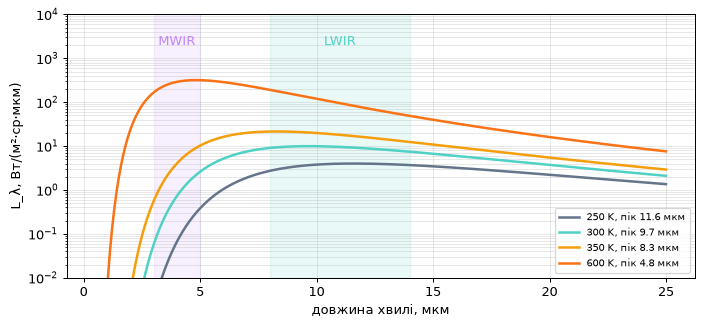

In [2]:
for T in (300.0, 310.0, 600.0):
    print(f'{T:5.0f} K: пік {S.WIEN_B / T * 1e6:5.2f} мкм · у 8–14 мкм {S.band_fraction(T, 8, 14):6.1%} · '
          f'у 3–5 мкм {S.band_fraction(T, 3, 5):6.1%}')
print(f'контраст на +1 K при 300 K: LWIR {np.pi * S.dL_dT(300.0):.2f} Вт/м², MWIR {np.pi * S.dL_dT(300.0, 3, 5):.2f} Вт/м² '
      f'(× π — у півсферу)')
print(f'відносний контраст (dL/dT)/L: LWIR {S.dL_dT(300.0) / S.band_radiance(300.0):.2%}/K, '
      f'MWIR {S.dL_dT(300.0, 3, 5) / S.band_radiance(300.0, 3, 5):.2%}/K')
P.planck_figure(); plt.show()

**Що бачимо.** Абсолютний сигнал +1 K у LWIR більший у ~12 разів — тому для об'єктів кімнатної температури
неохолоджуваний мікроболометр працює. Відносний контраст (на одиницю фону) більший у MWIR — звідси вища якість
охолоджуваних MWIR-камер на далеких цілях, але це вже охолоджуваний детектор.

## 2. Та сама сцена: година доби, ε і відбиття
Слайди «LWIR · емісивність» і «LWIR · умови». Подивіться на лист металу (ε = 0.07): він на ~27 K «холодніший» за фізичну температуру, холодніший за траву й асфальт
і лише трохи тепліший за саме небо — бо дзеркалить ясне небо, а не випромінює власне тепло. Вікно — непрозоре в LWIR (ε ≈ 0.9).
Таблиця під кадром: температура поверхні з GT проти яскравісної температури з raw (як показав би радіометричний тепловізор).

In [3]:
P.scene_panel();

interactive(children=(FloatSlider(value=21.0, continuous_update=False, description='hour', max=24.0, step=0.5)…

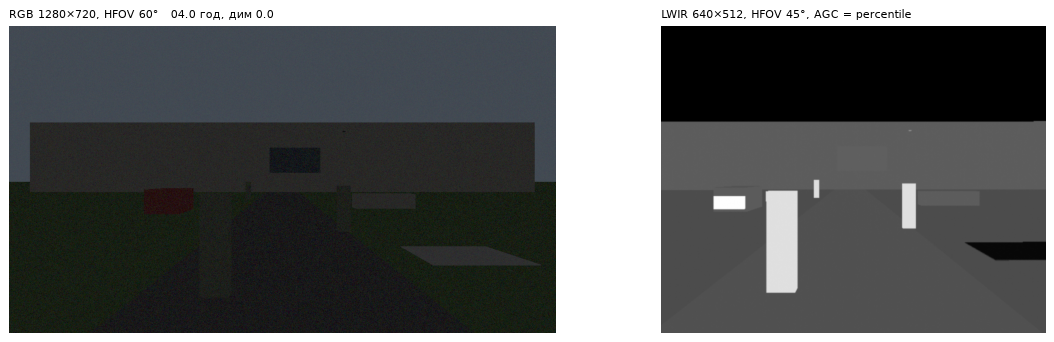

людина 18 м   : T поверхні   31.0 °C, ε = 0.98, яскравісна T   30.2 °C
лист металу   : T поверхні    5.1 °C, ε = 0.07, яскравісна T  -22.1 °C
вікно         : T поверхні    4.1 °C, ε = 0.90, яскравісна T    2.9 °C
бетонні блоки : T поверхні    3.1 °C, ε = 0.92, яскравісна T    2.2 °C
повітря 5.2 °C, ясне небо -24.8 °C


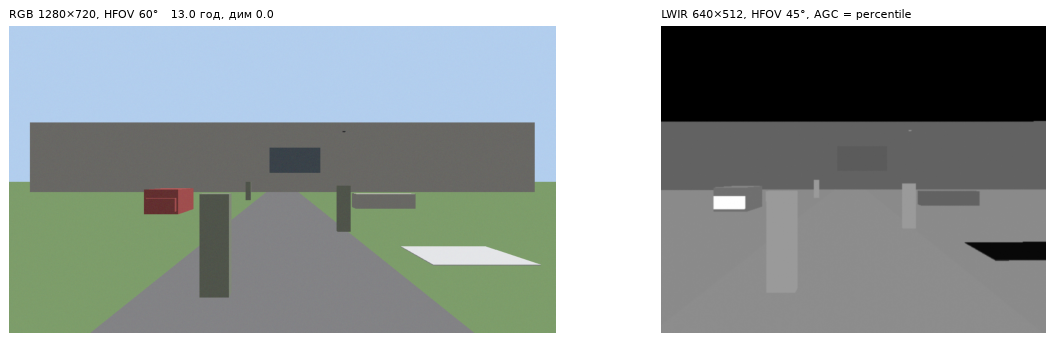

людина 18 м   : T поверхні   33.9 °C, ε = 0.98, яскравісна T   33.3 °C
лист металу   : T поверхні   23.2 °C, ε = 0.07, яскравісна T   -8.9 °C
вікно         : T поверхні   18.7 °C, ε = 0.90, яскравісна T   17.3 °C
бетонні блоки : T поверхні   20.5 °C, ε = 0.92, яскравісна T   19.2 °C
повітря 18.1 °C, ясне небо -11.9 °C


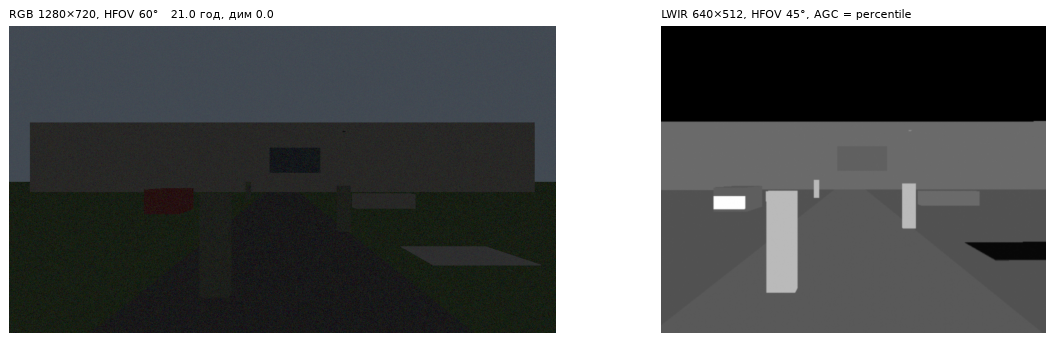

людина 18 м   : T поверхні   31.0 °C, ε = 0.98, яскравісна T   30.3 °C
лист металу   : T поверхні   12.5 °C, ε = 0.07, яскравісна T  -15.4 °C
вікно         : T поверхні   11.5 °C, ε = 0.90, яскравісна T   10.1 °C
бетонні блоки : T поверхні   13.9 °C, ε = 0.92, яскравісна T   12.6 °C
повітря 12.0 °C, ясне небо -18.0 °C


In [4]:
for hour in (4.0, 13.0, 21.0):
    P.scene_panel(static=dict(hour=hour, smoke=0.0, agc_mode='percentile'))

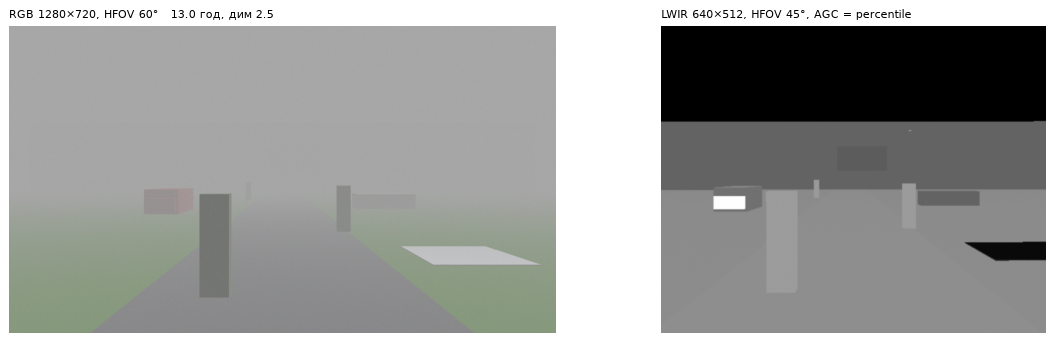

людина 18 м   : T поверхні   33.9 °C, ε = 0.98, яскравісна T   33.1 °C
лист металу   : T поверхні   23.2 °C, ε = 0.07, яскравісна T   -8.6 °C
вікно         : T поверхні   18.7 °C, ε = 0.90, яскравісна T   17.3 °C
бетонні блоки : T поверхні   20.5 °C, ε = 0.92, яскравісна T   19.2 °C
повітря 18.1 °C, ясне небо -11.9 °C


In [5]:
# дим: RGB «тоне» в серпанку, LWIR майже не змінюється (частинки диму ≪ 10 мкм)
P.scene_panel(static=dict(hour=13.0, smoke=2.5, agc_mode='percentile'))

## 3. Thermal crossover
Слайд «LWIR · умови». Добова модель з тепловою інерцією: трава гріється й остигає швидко, бетонні блоки — повільно.
Де криві перетинаються — контраст нуль, і T-гілка детектора «сліпне».

бетонні блоки = трава о 6.9, 17.2 год (світанок і вечір)
людина = розігрітий асфальт з 13.7 до 16.9 год — людина на дорозі «зникає» вдень
макс. асфальт 35.0 °C, людина 33.6 °C о 14:00


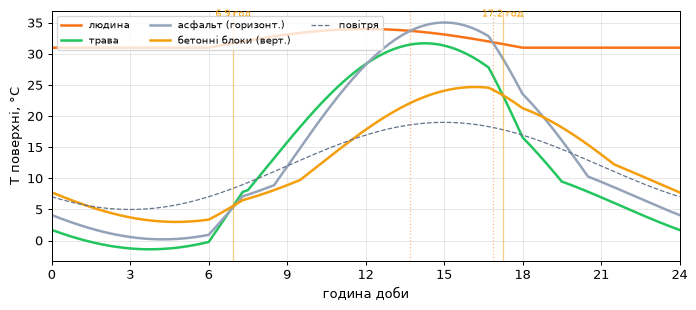

In [6]:
h, c = P.diurnal_curves()
x1 = P.crossovers(h, c['бетонні блоки (верт.)'], c['трава'])
x2 = P.crossovers(h, c['людина'], c['асфальт (горизонт.)'])
print('бетонні блоки = трава о', ', '.join(f'{t:.1f}' for t in x1), 'год (світанок і вечір)')
print('людина = розігрітий асфальт з', ' до '.join(f'{t:.1f}' for t in x2), 'год — людина на дорозі «зникає» вдень')
print(f'макс. асфальт {c["асфальт (горизонт.)"].max():.1f} °C, людина {np.interp(14, h, c["людина"]):.1f} °C о 14:00')
P.diurnal_figure(); plt.show()

In [7]:
# контраст людини 18 м на асфальтовій смузі у кадрі LWIR протягом доби (у K яскравісної температури)
core = S.Core()
road = (S.material_map(S.t_ids().ravel(), S.geometry(S.T_CAM, S.T_T_BODY)['P']).reshape(S.T_CAM.H, S.T_CAM.W) == 'асфальт')
m = S.object_px('людина 18 м', 't')
for hour in (2, 6, 9, 12, 14, 16, 18, 22):
    L, _, _ = S.thermal_radiance(hour)
    Tb = S.T_from_radiance(L)
    print(f'{hour:2d}:00  людина {np.median(Tb[m]) - 273.15:5.1f} °C, асфальт {np.median(Tb[road]) - 273.15:5.1f} °C, '
          f'ΔT = {np.median(Tb[m]) - np.median(Tb[road]):+5.1f} K')

 2:00  людина  30.3 °C, асфальт   0.3 °C, ΔT = +30.0 K
 6:00  людина  30.3 °C, асфальт  -0.1 °C, ΔT = +30.4 K
 9:00  людина  32.4 °C, асфальт  10.6 °C, ΔT = +21.8 K


12:00  людина  33.4 °C, асфальт  26.5 °C, ΔT =  +6.9 K
14:00  людина  33.0 °C, асфальт  32.4 °C, ΔT =  +0.7 K
16:00  людина  32.0 °C, асфальт  32.4 °C, ΔT =  -0.5 K


18:00  людина  30.5 °C, асфальт  22.0 °C, ΔT =  +8.4 K
22:00  людина  30.3 °C, асфальт   6.5 °C, ΔT = +23.9 K


### Реальні дані: контраст людини в LWIR і RGB, день проти ночі
Синтетика показала механізм; перевіримо його на розмітці реальних датасетів. Для кожної людини — медіана T у центральній
частині боксу мінус медіана кільця навколо, у рівнях 8-біт T-кадру (так їх віддають камери після AGC), і те саме для сірого RGB.
Малий |ΔT| — людину погано видно в LWIR, малий |ΔRGB| — у RGB. Умова: LLVIP — за сценою (2 денні сцени з 26),
FLIR — за яскравістю неба (поріг `R.DAY_SKY`, Demo 3).

умова       людей  |ΔT| мед.  |ΔT| < 8  |ΔRGB| мед.  |ΔRGB| < 8
LLVIP ніч    1840       39.0       12%         12.0         35%
LLVIP день    266       40.0       12%         17.0         33%
FLIR ніч     1117       60.5        3%         13.5         29%
FLIR день    2681        9.0       44%         20.5         21%


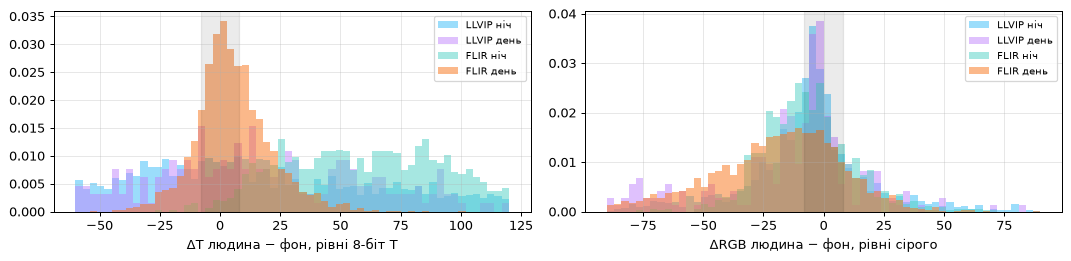

In [8]:
import rgbt12 as R
if R.available():
    rows = R.person_contrast(R.flir_pairs('validation') + R.llvip_pairs('test'))
    grp = lambda r: R.COND_NAMES[r['cond']]
    print(f'{"умова":10s} {"людей":>6s} {"|ΔT| мед.":>10s} {"|ΔT| < 8":>9s} {"|ΔRGB| мед.":>12s} {"|ΔRGB| < 8":>11s}')
    fig, ax = plt.subplots(1, 2, figsize=(12, 3))
    for g, col in (('LLVIP ніч', P.C_RGB), ('LLVIP день', '#C084FC'), ('FLIR ніч', P.C_F), ('FLIR день', P.C_T)):
        dT = np.array([r['dT'] for r in rows if grp(r) == g]); dC = np.array([r['dRGB'] for r in rows if grp(r) == g])
        print(f'{g:10s} {len(dT):6d} {np.median(np.abs(dT)):10.1f} {np.mean(np.abs(dT) < 8):9.0%} '
              f'{np.median(np.abs(dC)):12.1f} {np.mean(np.abs(dC) < 8):11.0%}')
        ax[0].hist(dT, bins=60, range=(-60, 120), alpha=0.5, color=col, density=True, label=g)
        ax[1].hist(dC, bins=60, range=(-90, 90), alpha=0.5, color=col, density=True, label=g)
    ax[0].set_xlabel('ΔT людина − фон, рівні 8-біт T'); ax[1].set_xlabel('ΔRGB людина − фон, рівні сірого')
    for a in ax:
        a.axvspan(-8, 8, color='k', alpha=0.08); a.legend(fontsize=8); a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
else:
    print(f'Реальних даних немає — завантажте: {R.FETCH}')

**Що бачимо.** На денних кадрах FLIR медіанний |ΔT| людини — лише кілька рівнів 8-біт T, і в помітної частки
людей він менший за 8 рівнів: людина зливається з нагрітим сонцем фоном — це реальний crossover, той самий механізм,
що в моделі вище. Уночі контраст у LWIR у рази більший, а в RGB — навпаки, падає. LLVIP «день» — одна-дві сцени,
і тепловий контраст там лишається високим: висновок «вдень T слабшає» залежить від сцени, сезону й години, а не лише від
слова «день». Звідси спліт за умовами і fusion, а не «лише тепловізор».

## 4. Мікроболометр: NETD у counts і тепловий час τ
Слайд «Сенсори · мікроболометр». У ядра немає затвора-експозиції: кожен піксель — термометр з тепловою інерцією τ ≈ 8–12 мс.
При обертанні гімбала кадр «розмазується» на `ω·τ / IFOV` пікселів — у бік, протилежний руху.

In [9]:
core = S.Core()
print(f'NETD 50 мК → σ шуму = {core.sigma:.1f} counts;  1 K при 300 K = {core.counts_per_K():.0f} counts;  '
      f'14 біт = {2**14} рівнів ≈ {2**14 / core.counts_per_K():.0f} K діапазону')
ifov = S.T_CAM.ifov_deg
for omega, tau in ((30, 0.010), (90, 0.010), (300, 0.008)):
    print(f'ω = {omega:3d} °/с, τ = {tau * 1e3:.0f} мс: зсув за τ = {omega * tau:.2f}° = {omega * tau / ifov:4.1f} px '
          f'(IFOV {ifov:.3f}°/px)')

NETD 50 мК → σ шуму = 7.6 counts;  1 K при 300 K = 151 counts;  14 біт = 16384 рівнів ≈ 108 K діапазону
ω =  30 °/с, τ = 10 мс: зсув за τ = 0.30° =  4.3 px (IFOV 0.070°/px)
ω =  90 °/с, τ = 10 мс: зсув за τ = 0.90° = 12.8 px (IFOV 0.070°/px)
ω = 300 °/с, τ = 8 мс: зсув за τ = 2.40° = 34.1 px (IFOV 0.070°/px)


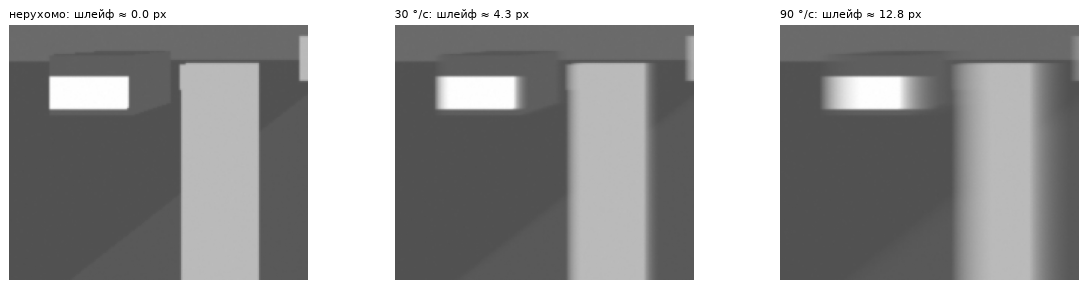

In [10]:
L, _, _ = S.thermal_radiance(21.0)
lohi = np.percentile(core.raw(L), (0.5, 99.9))            # один фіксований мапінг на всі три кадри
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
for a, (om, title) in zip(ax, ((0, 'нерухомо'), (30, '30 °/с'), (90, '90 °/с'))):
    blur = om * 0.010 / ifov
    raw = core.raw(L, tau_blur_px=blur)
    a.imshow(S.agc(raw, 'fixed', lo_hi=lohi)[250:420, 60:260], cmap='gray', vmin=0, vmax=255); a.set_title(f'{title}: шлейф ≈ {blur:.1f} px', loc='left', fontsize=9)
    a.set_axis_off()
plt.tight_layout(); plt.show()

## 5. AGC: 14 біт → 8 біт
Слайд «Сигнал · AGC». У кут кадру потрапляє гаряче джерело 600 K (вихлоп, ракетниця) площею 144 px (0.04 % кадру).
Скільки «сірого» лишається людині 18 м за різних AGC?

AGC           без джерела   з джерелом
minmax                185          110   Δ = -75 рівнів
percentile            186          186   Δ = +0 рівнів
histeq                248          248   Δ = +0 рівнів
fixed                 186          186   Δ = +0 рівнів


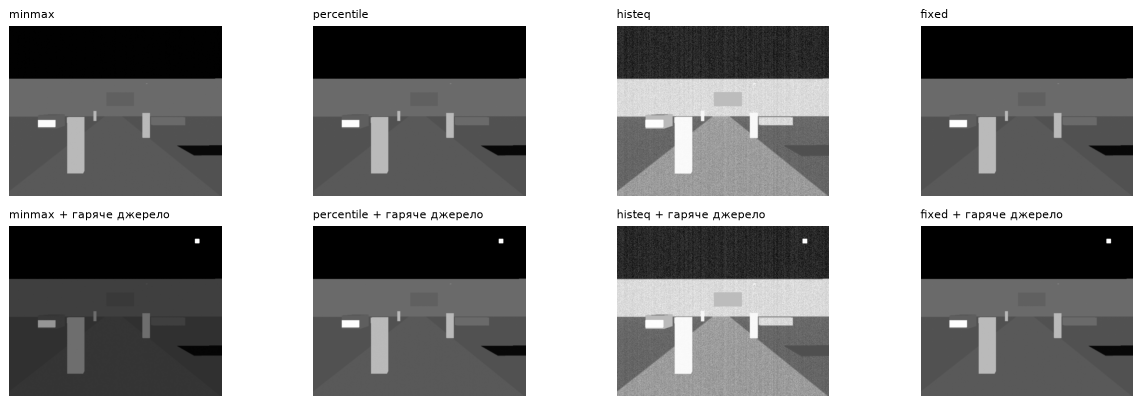

In [11]:
raw0, raw1, rows = P.agc_hot_source()
print(f'{"AGC":12s} {"без джерела":>12s} {"з джерелом":>12s}')
for mode, a, b, _, _ in rows:
    print(f'{mode:12s} {a:12.0f} {b:12.0f}   Δ = {b - a:+.0f} рівнів')
fig, ax = plt.subplots(2, 4, figsize=(14, 4.6))
for j, (mode, _, _, a, b) in enumerate(rows):
    ax[0, j].imshow(a, cmap='gray', vmin=0, vmax=255); ax[0, j].set_title(f'{mode}', loc='left', fontsize=9)
    ax[1, j].imshow(b, cmap='gray', vmin=0, vmax=255); ax[1, j].set_title(f'{mode} + гаряче джерело', loc='left', fontsize=9)
for a in ax.ravel():
    a.set_axis_off()
plt.tight_layout(); plt.show()

Min–max ділить діапазон на одну гарячу точку — людина темніє вдвічі між двома сусідніми кадрами. Перцентиль
(0.5–99.9) і фіксований мапінг з train-статистик стабільні, поки джерело менше за 0.1 % кадру. Для мережі це різні
домени: тренувати на одному AGC і запускати на іншому — гарантоване падіння.

### Реальні дані: AGC двох датасетів — два домени
LLVIP і FLIR-aligned віддають T уже як 8 біт після AGC своїх камер. Та сама людина в них має різний «рівень сірого»,
а середнє кадру гуляє від кадру до кадру, бо AGC підлаштовується під сцену. Для мережі це різні домени.

In [12]:
if R.available():
    print(f'{"датасет":12s} {"mean T":>7s} {"std T":>6s} {"p1":>4s} {"p99":>4s} {"середнє кадру min…max":>22s} {"|Δ сусідніх кадрів| p95":>24s}')
    for name, pairs in (('LLVIP test', R.llvip_pairs('test')[:400]), ('FLIR val', R.flir_pairs('validation')[:400])):
        T = np.stack([R.read_pair(p, (160, 128))[1] for p in pairs]).astype(np.float32)
        fm = T.mean((1, 2))
        print(f'{name:12s} {T.mean():7.1f} {T.std():6.1f} {np.percentile(T, 1):4.0f} {np.percentile(T, 99):4.0f} '
              f'{fm.min():10.0f} … {fm.max():<9.0f} {np.percentile(np.abs(np.diff(fm)), 95):24.1f}')
else:
    print(f'Реальних даних немає — завантажте: {R.FETCH}')

датасет       mean T  std T   p1  p99  середнє кадру min…max  |Δ сусідніх кадрів| p95


LLVIP test      86.8   52.9    1  209         47 … 109                           16.1


FLIR val       135.1   65.9   15  251        104 … 163                            7.9


## 6. Пастка: 14-біт raw у 16-бітному TIFF
Ultralytics 8.4 (`utils/patches.py::imread`) перетворює uint16 на uint8 зсувом `im >> 8`. Для 14-бітного raw (0…16383)
це лишає 0…63 — лише 64 рівні, а реальна сцена займає ще менше.

In [13]:
raw = core.raw(S.thermal_radiance(21.0)[0])
hi_byte = (raw >> 8).astype(np.uint8)                  # те саме, що imread для 16-біт
own = S.agc(raw, 'fixed', lo_hi=np.percentile(raw, (0.5, 99.9)))
print(f'raw: {raw.min()}…{raw.max()}, унікальних рівнів {len(np.unique(raw))}')
print(f'>> 8: {hi_byte.min()}…{hi_byte.max()}, унікальних рівнів {len(np.unique(hi_byte))}')
print(f'власний мапінг (фікс. перцентилі train): унікальних рівнів {len(np.unique(own))}')
m = S.object_px('людина 45 м', 't')
print(f'людина 45 м: >>8 дає рівні {np.unique(hi_byte[m])[:8]}, власний мапінг — {len(np.unique(own[m]))} рівнів')

raw: 2498…10767, унікальних рівнів 2109
>> 8: 9…42, унікальних рівнів 28
власний мапінг (фікс. перцентилі train): унікальних рівнів 135
людина 45 м: >>8 дає рівні [29 30 31 33], власний мапінг — 13 рівнів


Висновок: 14-біт raw масштабуємо самі (фіксовані LO/HI з train) і пишемо вже 8-бітний T-канал — або
передаємо `cv2.IMREAD_ANYDEPTH` у власному loader-і.

### Реальний 14-біт raw
Якщо є 16-біт TIFF тепловізора (FLIR ADAS v2 дає 14/16-біт кадри без AGC; `python tools/fetch_flir_adas.py --raw16`),
та сама перевірка на реальному кадрі: скільки рівнів лишає `>> 8` і скільки — власний мапінг з фіксованими LO / HI.

video-zp8ed5vPKfAJ2fKWh-frame-006374-q9vpgzzv7dPWnjHFi.tiff: (512, 640), uint16, 6413…9749, унікальних рівнів 1854
>> 8: 25…38, унікальних рівнів 14; власний мапінг (LO 6226, HI 7999): 230 рівнів


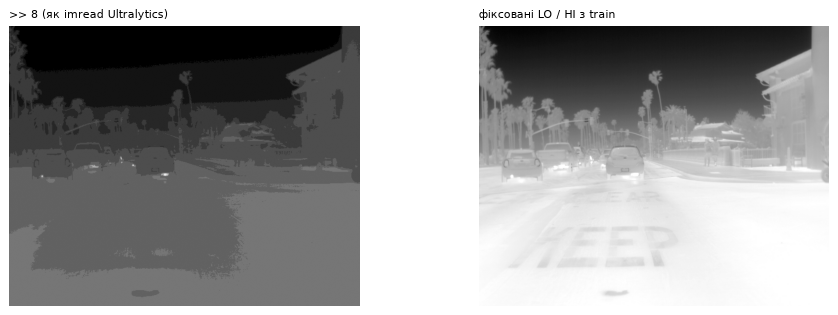

In [14]:
frames = R.raw16_frames()
if frames:
    raws = [cv2.imread(str(f), cv2.IMREAD_UNCHANGED) for f in frames]
    lo, hi = np.percentile(np.stack(raws[: len(raws) // 2]), (0.5, 99.9))       # LO / HI — з «train»-половини
    raw = raws[-1]
    own = np.clip((raw.astype(np.float32) - lo) / (hi - lo) * 255, 0, 255).astype(np.uint8)
    print(f'{frames[-1].name}: {raw.shape}, {raw.dtype}, {raw.min()}…{raw.max()}, унікальних рівнів {len(np.unique(raw))}')
    print(f'>> 8: {(raw >> 8).min()}…{(raw >> 8).max()}, унікальних рівнів {len(np.unique(raw >> 8))}; '
          f'власний мапінг (LO {lo:.0f}, HI {hi:.0f}): {len(np.unique(own))} рівнів')
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].imshow(raw >> 8, cmap='gray'); ax[0].set_title('>> 8 (як imread Ultralytics)', loc='left', fontsize=9)
    ax[1].imshow(own, cmap='gray'); ax[1].set_title('фіксовані LO / HI з train', loc='left', fontsize=9)
    for a in ax:
        a.set_axis_off()
    plt.tight_layout(); plt.show()
else:
    print('16-біт TIFF немає (FLIR ADAS v2: https://adas-dataset-v2.flirconservator.com/). '
          'Завантажте кадри: python tools/fetch_flir_adas.py --raw16')

## 7. FFC: замерзлі кадри і стрибок offset
Слайд «Сигнал · NUC / FFC». Потік 30 Гц, статична сцена: між FFC offset повзе з нагрівом корпусу, під час FFC (0.4 с)
ядро повторює останній кадр, після FFC — стрибок. Guard порівнює **raw біт-у-біт**: після AGC і H.264 повтор уже не точний.

кадрів 450, замерзлих 24, телеметрія FFC 24, збіг guard і телеметрії 100%
стрибок середнього після першого FFC: +96 counts ≈ +0.63 K


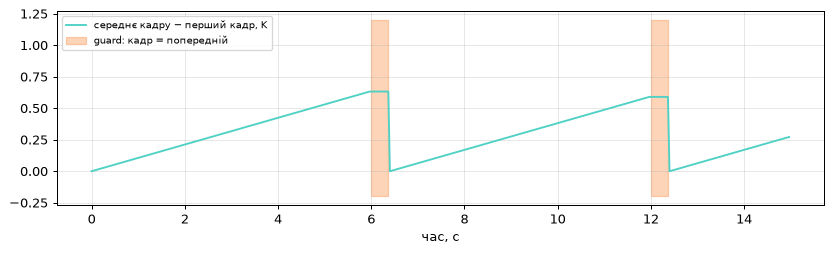

In [15]:
stream = S.thermal_stream()
prev = None; frozen, tel, mean = [], [], []
for t, raw, telem in stream:
    frozen.append(prev is not None and np.array_equal(raw, prev))
    tel.append(telem['ffc_in_progress']); mean.append(raw.mean()); prev = raw
frozen, tel, mean = map(np.array, (frozen, tel, mean))
tt = np.array([s[0] for s in stream])
print(f'кадрів {len(stream)}, замерзлих {frozen.sum()}, телеметрія FFC {tel.sum()}, збіг guard і телеметрії {(frozen == tel).mean():.0%}')
k = np.where(np.diff(tel.astype(int)) == -1)[0][0] + 1
print(f'стрибок середнього після першого FFC: {mean[k - 1] - mean[k]:+.0f} counts ≈ '
      f'{(mean[k - 1] - mean[k]) / core.counts_per_K():+.2f} K')
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.plot(tt, (mean - mean[0]) / core.counts_per_K(), color='#4FD1C5', label='середнє кадру − перший кадр, K')
ax.fill_between(tt, -0.2, 1.2, where=frozen, color='#F97316', alpha=0.3, label='guard: кадр = попередній')
ax.set_xlabel('час, с'); ax.legend(fontsize=8, loc='upper left'); ax.grid(alpha=0.3); plt.show()

## Питання

1. Чому лист металу на кадрі LWIR «холодніший» за траву, хоча його фізична температура — як у повітря? Що буде вночі під хмарами?
2. О котрій годині у вашому регіоні crossover для техніки на ґрунті? Як закласти це у спліт day / night / crossover?
3. Ваш loader читає 16-бітні TIFF через `cv2.imread(..., IMREAD_UNCHANGED)` — скільки рівнів отримує мережа?
4. Що зробить трекер із заняття 9, якщо FFC-кадр позначити як «немає вимірювання», а не як звичайний кадр?